# Veri ayrımı ve geliştirme kümesinde EDA

Stratified %80/%20 ayrım eğitimden önce sabitlenir. EDA geliştirme kümesiyle sınırlıdır. Test sınıf oranları yalnızca nihai değerlendirmede yazılır.

In [1]:
from pathlib import Path
import subprocess
import sys

ROOT = Path.cwd()
if not (ROOT / "src/experiment.py").exists():
    ROOT = ROOT / "YapayS-Vize"
    if not ROOT.exists():
        subprocess.run(["git", "clone", "https://github.com/JustLotus/YapayS-Vize.git",
                        str(ROOT)], check=True)
import pandas as pd
from IPython.display import Image, display

def table(name, maximum=None):
    frame = pd.read_csv(ROOT / "results" / name)
    if maximum is not None:
        frame = frame.head(maximum)
    display(frame.round(4))

def figure(name, width=680):
    display(Image(filename=str(ROOT / "figures" / name), width=width))


In [2]:
# Yeniden üretmek için temiz bir depo kopyasında True yapın.
RUN_EXPERIMENT = False
if RUN_EXPERIMENT:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    str(ROOT / "requirements.txt")], check=True)
    for stage in ('prepare',):
        subprocess.run([sys.executable, "src/experiment.py", stage], cwd=ROOT, check=True)


In [3]:
table("class_distribution.csv")
table("numeric_summary.csv")
table("special_values.csv")
table("categorical_frequencies.csv", 25)
table("numeric_by_target.csv")
table("outlier_flags.csv", 8)


,class,count,ratio
0,0,2934,0.8904
1,1,361,0.1096


,feature,count,mean,std,min,25%,50%,75%,max,IQR,IQR_outliers
0,age,3295.0,40.1229,10.2679,18.000,32.000,38.000,47.000,86.000,15.000,29
1,campaign,3295.0,2.5314,2.5300,1.000,1.000,2.000,3.000,29.000,2.000,190
2,pdays,134.0,5.8284,3.8536,0.000,3.000,6.000,6.000,21.000,3.000,16
3,previous,3295.0,0.1879,0.5401,0.000,0.000,0.000,0.000,6.000,0.000,471
4,emp.var.rate,3295.0,0.0870,1.5635,-3.400,-1.800,1.100,1.400,1.400,3.200,0
5,cons.price.idx,3295.0,93.5796,0.5789,92.201,93.075,93.444,93.994,94.767,0.919,0
6,cons.conf.idx,3295.0,-40.4921,4.5971,-50.800,-42.700,-41.800,-36.400,-26.900,6.300,34
7,euribor3m,3295.0,3.6239,1.7329,0.635,1.334,4.857,4.961,5.045,3.627,0
8,nr.employed,3295.0,5166.5345,73.7067,4963.600,5099.100,5191.000,5228.100,5228.100,129.000,0


,feature,missing,unknown,unique,pdays_999
0,age,0,0,66,0
1,job,0,32,12,0
2,marital,0,9,4,0
3,education,0,133,8,0
4,default,0,644,3,0
5,housing,0,83,3,0
6,loan,0,83,3,0
7,contact,0,0,2,0
8,month,0,0,10,0
9,day_of_week,0,0,5,0


,value,count,feature
0,admin.,801,job
1,blue-collar,689,job
2,technician,553,job
3,services,328,job
4,management,280,job
5,self-employed,132,job
6,retired,130,job
7,entrepreneur,114,job
8,unemployed,95,job
9,housemaid,88,job


,y,age,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,0,39.8858,2.5988,6.3000,0.1384,0.2403,93.6008,-40.5903,3.8017,5175.3331
1,1,42.0499,1.9834,5.5476,0.5900,-1.1593,93.4075,-39.6947,2.1787,5095.0249


,row_index,age,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,2761,False,False,False,False,False,False,False,False,False
1,591,False,False,False,False,False,False,False,False,False
2,1812,False,False,False,False,False,False,False,False,False
3,1504,False,False,False,False,False,False,False,False,False
4,1599,False,False,False,False,False,False,False,False,False
5,250,False,False,False,False,False,False,False,False,False
6,3772,False,False,False,False,False,False,False,False,False
7,2431,False,False,False,True,False,False,False,False,False


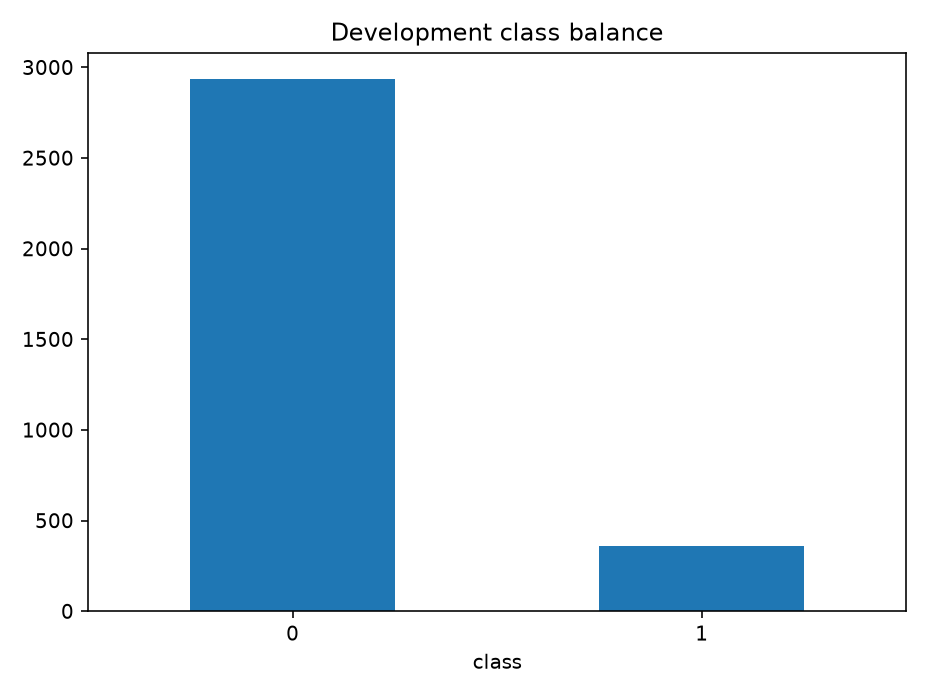

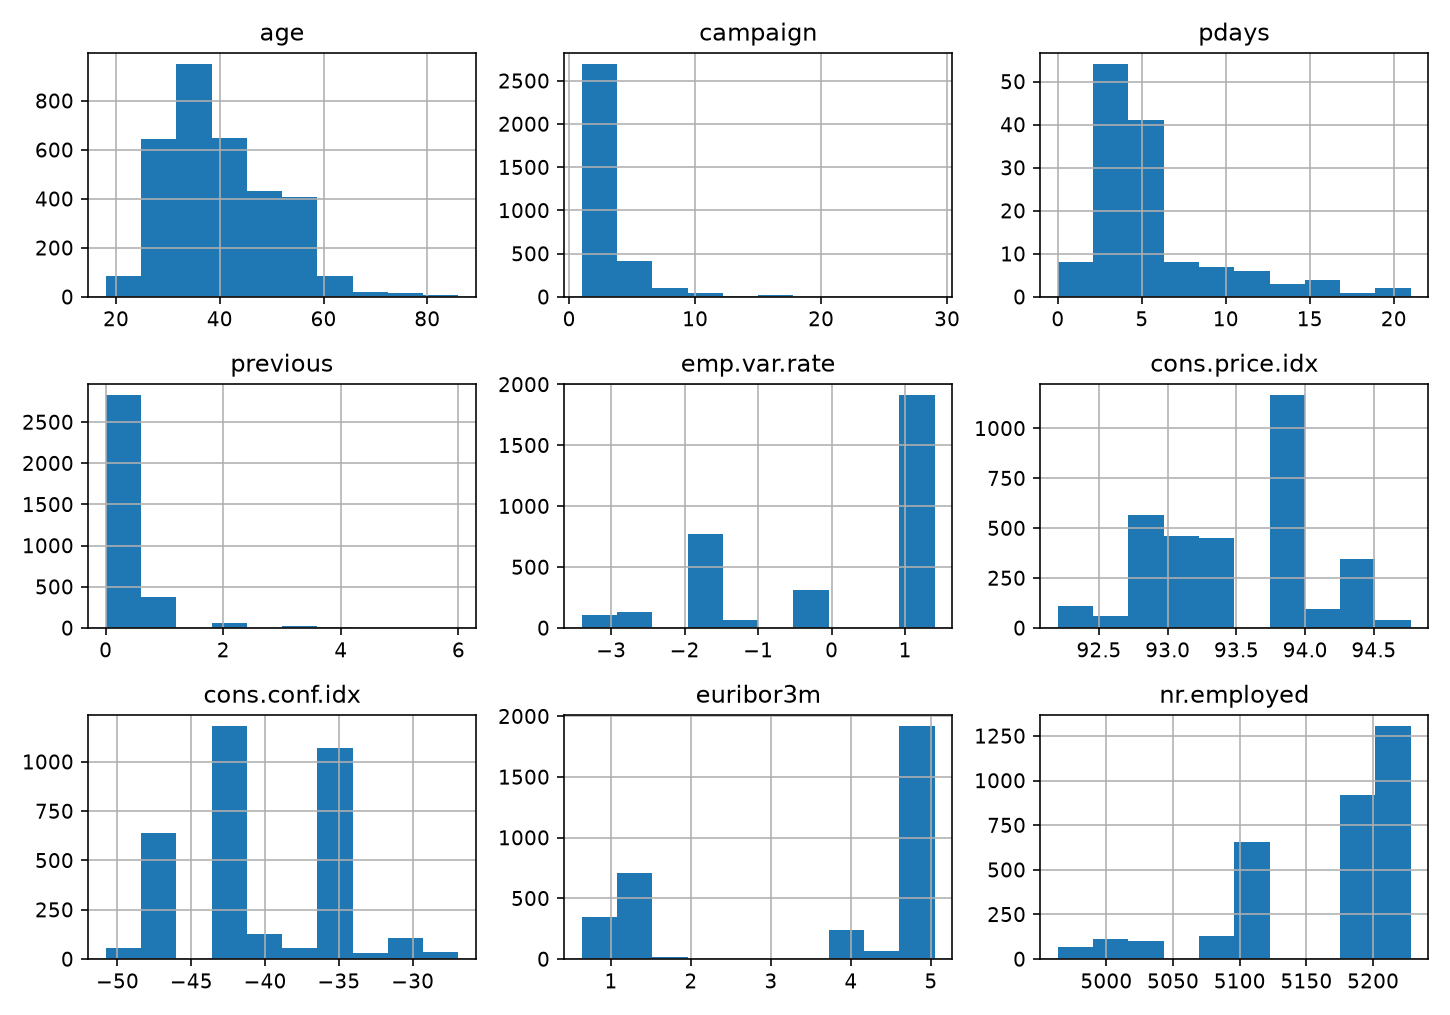

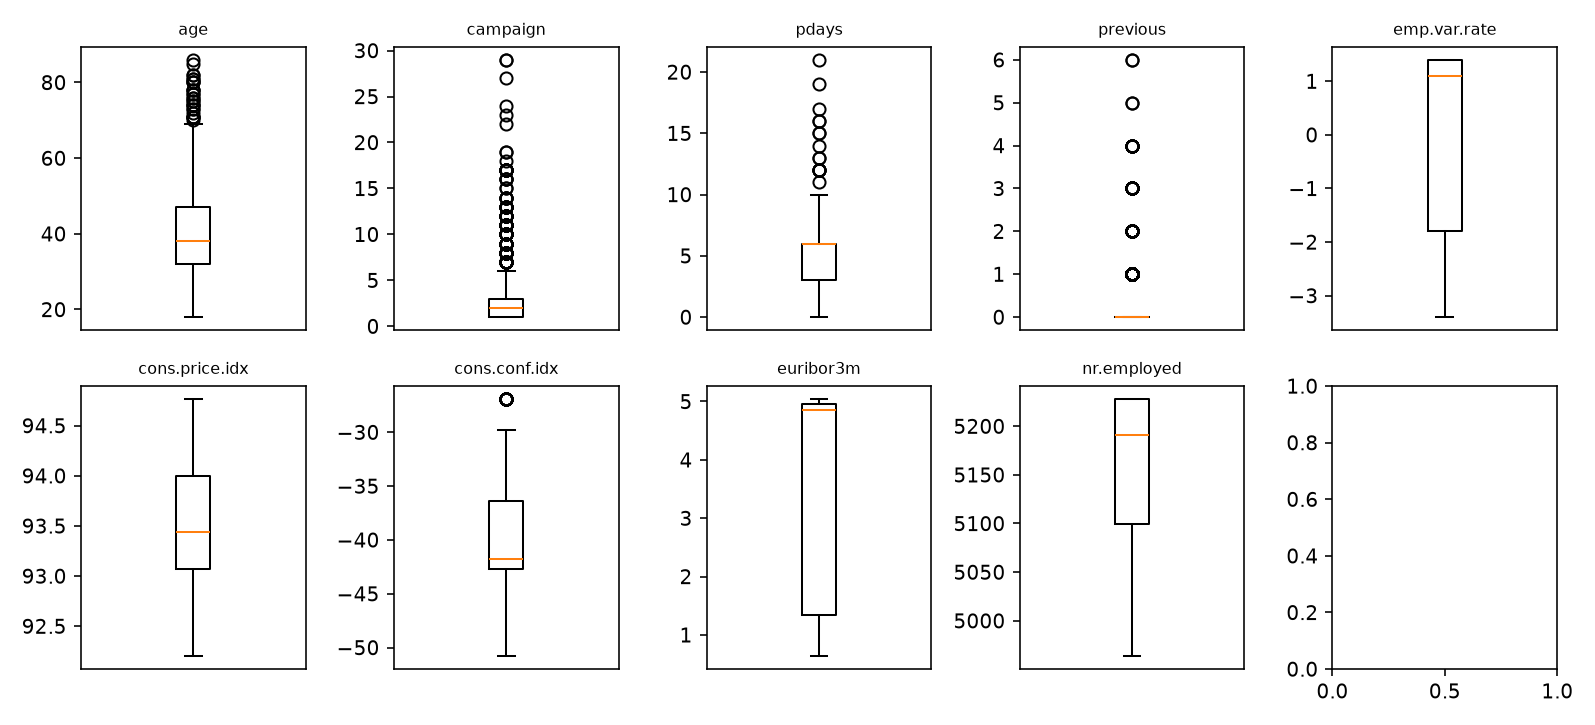

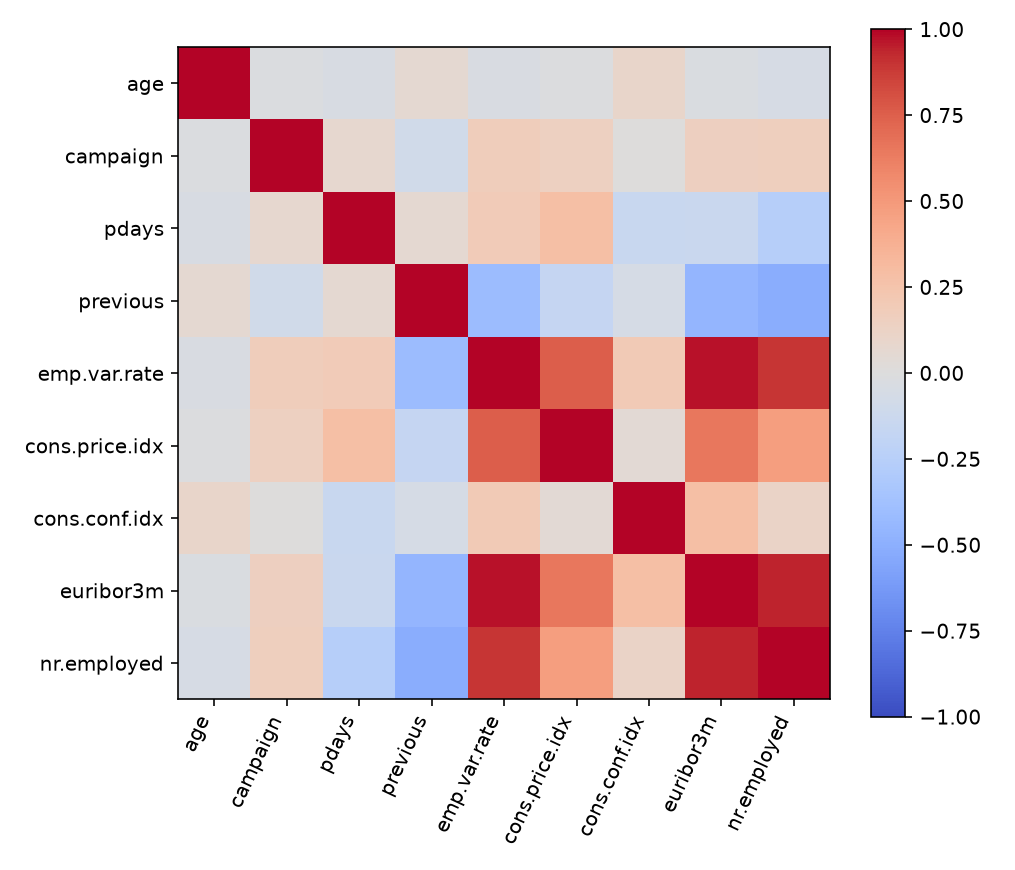

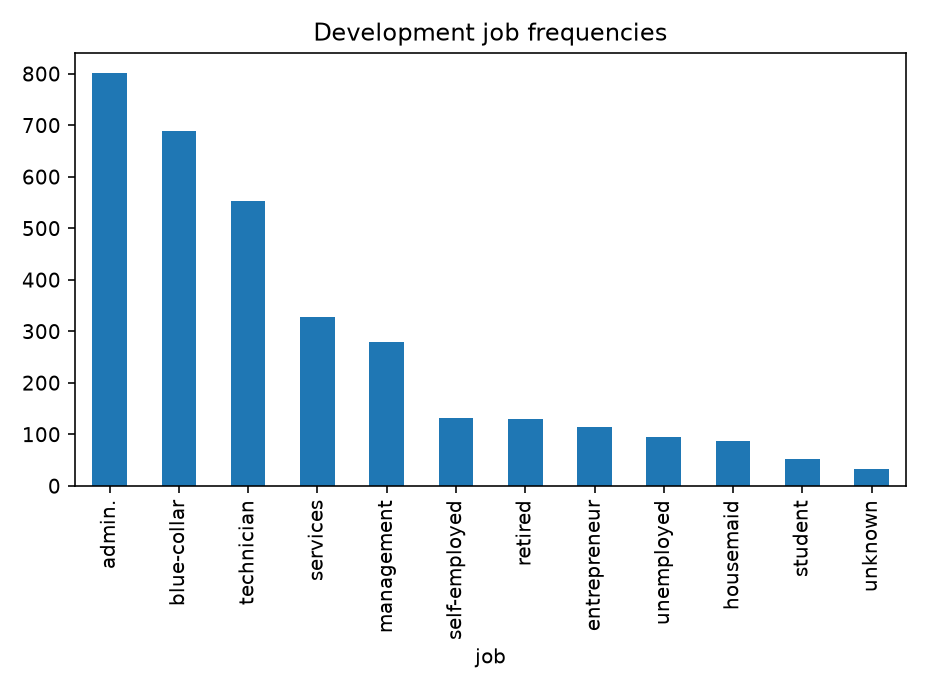

In [4]:
for name in ("eda_class_balance.png", "eda_histograms.png", "eda_boxplots.png",
             "eda_correlations.png", "eda_categories.png"):
    figure(name)